# ML Metrics (ROC Curve and Precision-Recall Curve)

## Исходные данные для построения

Как сохранить:   
`y_test.to_csv('y_test.csv', index=False)`  
`np.save('pred_proba.npy', pred_proba)`  

In [18]:
y_test = pd.read_csv('y_test.csv')
X_test = pd.read_csv('X_test.csv')
pred_proba = np.load('pred_proba.npy')

In [9]:
print(y_test)

      target_churn
0                1
1                1
2                0
3                1
4                0
...            ...
4776             0
4777             0
4778             1
4779             0
4780             0

[4781 rows x 1 columns]


In [10]:
print(pred_proba)

[0.95919897 0.72731883 0.         ... 0.73386773 0.63636902 0.        ]


## Код для построения

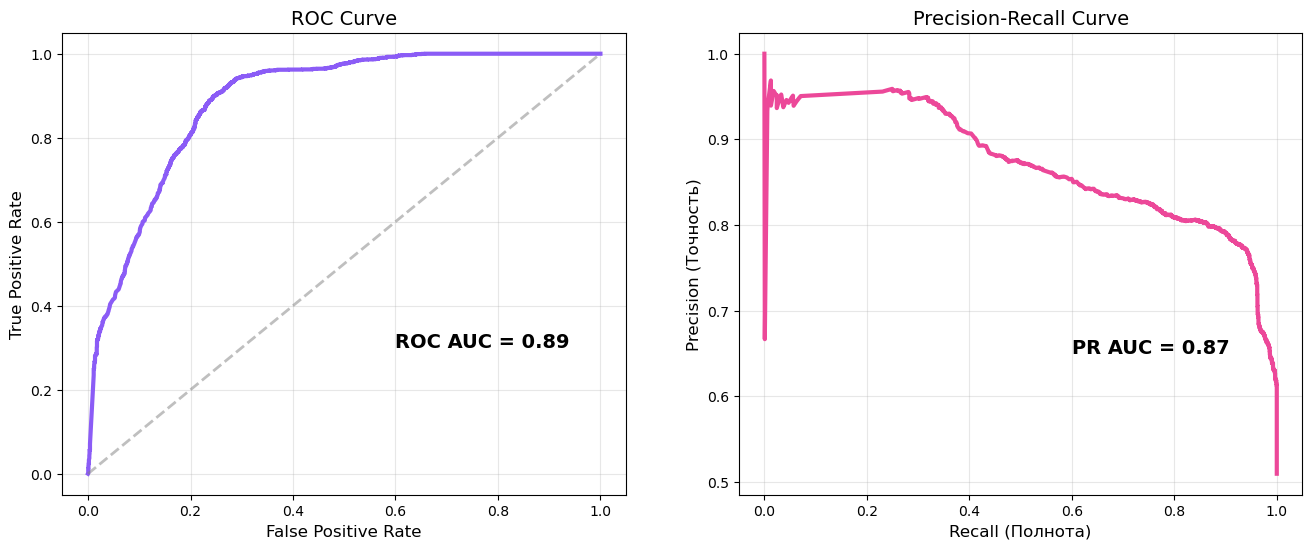

In [11]:
# =====================================================
# IMPORTS
# =====================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score

# =====================================================
# LOAD DATA
# =====================================================

y_test = pd.read_csv('y_test.csv')
X_test = pd.read_csv('X_test.csv')
pred_proba = np.load('pred_proba.npy')

# =====================================================
# PLOT
# =====================================================

# 1. Рассчитываем метрики
fpr, tpr, _ = roc_curve(y_test, pred_proba)
roc_auc = auc(fpr, tpr)

precision, recall, _ = precision_recall_curve(y_test, pred_proba)
pr_auc = average_precision_score(y_test, pred_proba)

# 2. Создаем два графика рядом (1 строка, 2 столбца)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Левый график: ROC
ax1.plot(fpr, tpr, color='#8B5CF6', lw=3, label=f'ROC AUC = {roc_auc:.2f}')
ax1.plot([0, 1], [0, 1], color='grey', alpha = 0.5, linestyle='--', lw=2)
ax1.set_xlabel('False Positive Rate', fontsize=12)
ax1.set_ylabel('True Positive Rate', fontsize=12)
ax1.set_title('ROC Curve', fontsize=14)
#ax1.legend(loc="lower right")
ax1.grid(alpha=0.3)
ax1.text(
    0.60,
    0.30,
    f'ROC AUC = {roc_auc:.2f}',
    fontsize=14,
    weight="bold"
)


# Правый график: PR
ax2.plot(recall, precision, color='#EC4899', lw=3, label=f'PR AUC = {pr_auc:.2f}')
ax2.set_xlabel('Recall (Полнота)', fontsize=12)
ax2.set_ylabel('Precision (Точность)', fontsize=12)
ax2.set_title('Precision-Recall Curve', fontsize=14)
#ax2.legend(loc="lower left")
ax2.grid(alpha=0.3)
ax2.text(
    0.60,
    0.65,
    f'PR AUC = {pr_auc:.2f}',
    fontsize=14,
    weight="bold",
)
plt.savefig('churn_model_performance.png', dpi=300, bbox_inches='tight')

plt.show()